In [3]:
import numpy as np
import matplotlib.pyplot as plt
import math

np.random.seed(847063)

# Discretas

Bernoulli

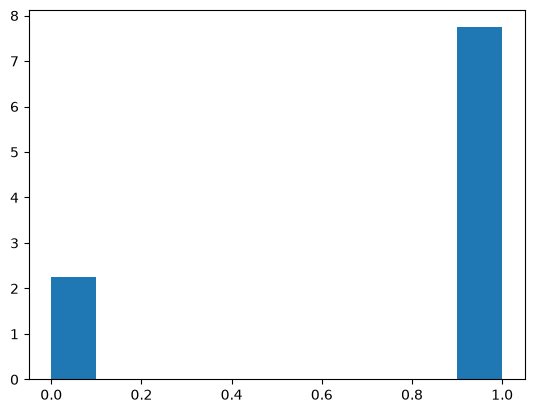

In [20]:
def bernoulli(p, M):
    valor = np.sum(np.random.uniform(size=M) < p)
    amostra = [1]*valor + [0]*(M-valor)
    return amostra

p = 0.75
M= 1000
dados = bernoulli(p, M)

plt.hist(dados, density=True)
plt.show()

Binomial

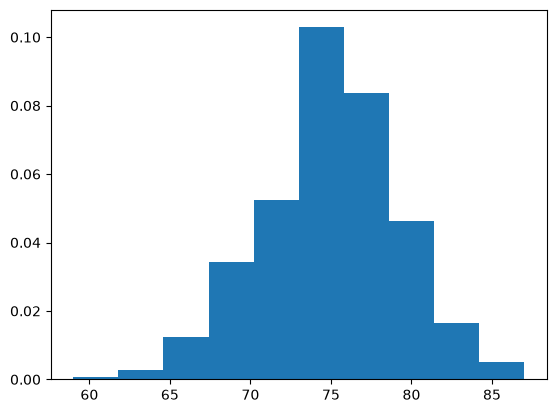

In [21]:
def binomial(n, p, M):
    amostra = []
    for i in range(M):
        amostra.append(np.sum(np.random.uniform(size=n) < p))
    
    return amostra

n = 100
p = 0.75
M = 1000

dados = binomial(n, p, M)

plt.hist(dados, density=True)
plt.show()

Binomial Recursiva

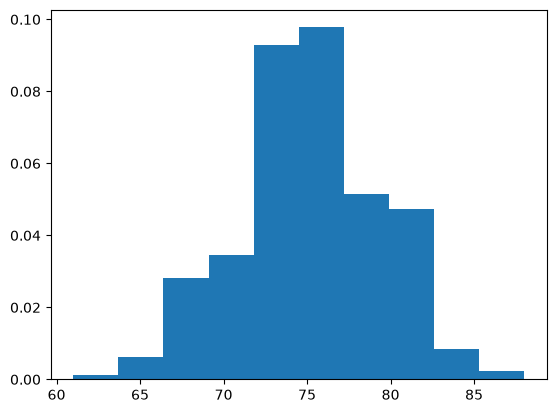

In [22]:
def binomial_recursiva(n, p, M):
  amostra = []
  for i in range(M):
    u = np.random.uniform(low=0, high=1)
    i = 0
    pi = (1-p)**n
    F = pi
    while u > F:
      pi = (n-i)/(i+1)*(p/(1-p))*pi
      i += 1
      F += pi
    amostra.append(i)
  return amostra

n = 100
p = 0.75
M = 1000

dados = binomial_recursiva(n, p, M)

plt.hist(dados, density=True)
plt.show()


Geométrica

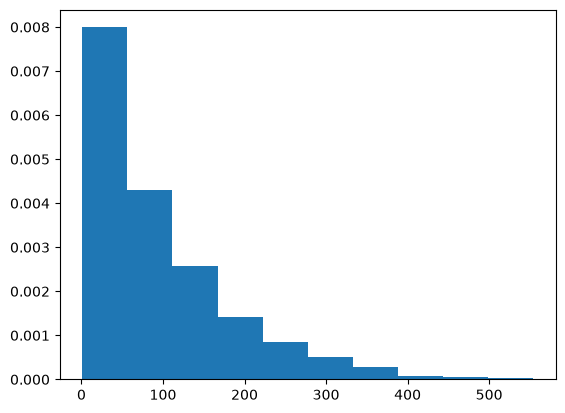

In [23]:
def geometrica(p, M):
  amostra = []
  for j in range(M):
    i = 1
    while np.sum(np.random.uniform() < p) == 0:
      i += 1
    amostra.append(i)
  return amostra

p = 0.01
M = 1000

dados = geometrica(p, M)

plt.hist(dados, density=True)
plt.show()

Geométrica por inversão

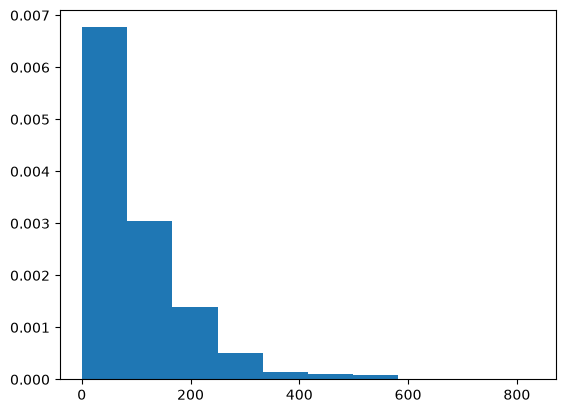

In [24]:
def geometrica_inverso(p, M):
  amostra = []
  for i in range(M):
    j = np.ceil(np.log(1 - np.random.uniform())/np.log(1-p))
    amostra.append(j)
  return amostra

p = 0.01
M = 1000

dados = geometrica_inverso(0.01, 1_000)

plt.hist(dados, density=True)
plt.show()

Poisson - Metodo recursivo

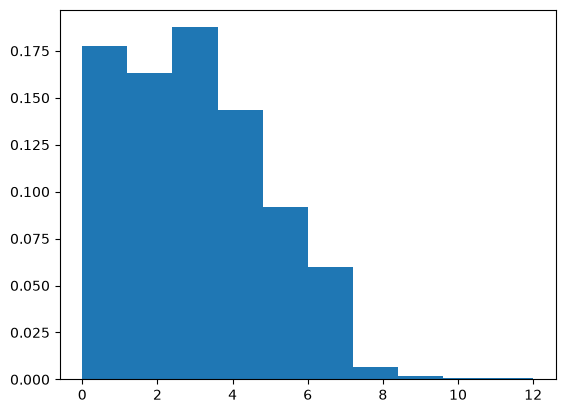

In [25]:
def poisson(lamb, M):
  amostra = []
  for j in range(M):
    i = 0
    p0 = np.exp(-lamb)
    F = p0
    u = np.random.uniform()
    while u > F:
      i += 1
      p0 = p0 * lamb/i
      F += p0
    amostra.append(i)
  return amostra

lam = 3
M = 1000

dados = poisson(lam, M)

plt.hist(dados, density=True)
plt.show()

Aproximação da Poisson por Binomial

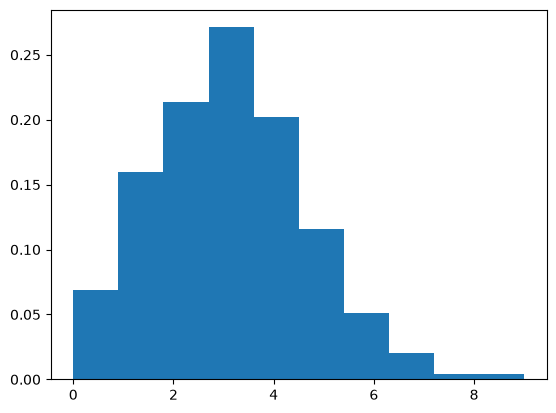

In [26]:
def poisson_bin(lam, n, M):
    amostra = np.sum(np.random.uniform(size=(M, n)) < lam/n, axis=1) #Utilizando operação de vetores do numpy para gerar a amostra completa
    return amostra

lam = 3
n = 1000
M = 500

dados = poisson_bin(lam, n, M)

plt.hist(dados, density=True)
plt.show()

Binomial Negativa via Bernoulli

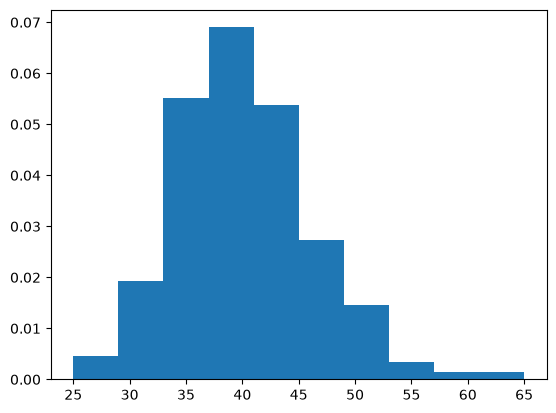

In [27]:
def bin_neg_bern(p, r, N):
    amostra = []
    for i in range(N):
        n = 0
        x = 0
        while x < r:
            if(np.random.uniform() < p):
                n += 1
                x += 1
            else:
                n +=1
        amostra.append(n)
    return amostra

p = 0.5
r = 20
N = 1000

dados = bin_neg_bern(p, r, N)

plt.hist(dados, density=True)
plt.show()

Binomial Negativa via soma de Geométricas

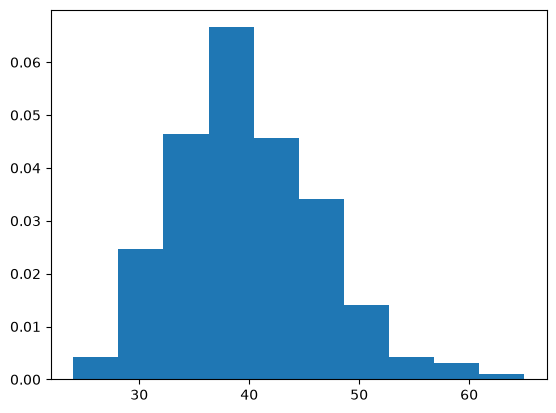

In [28]:
def geometrica_inverso_bin(p, r):
  n = []
  for i in range(r):
    j = np.ceil(np.log(1 - np.random.uniform())/np.log(1-p))
    n.append(j)
  return sum(n)

def bin_neg_geom(p, r, N):
  amostra = []
  for i in range(N):
    amostra.append(geometrica_inverso_bin(p, r))
  return amostra

p = 0.5
r = 20
N = 1000

dados = bin_neg_geom(p, r, N)

plt.hist(dados, density=True)
plt.show()

Binomial Negativa Recursiva

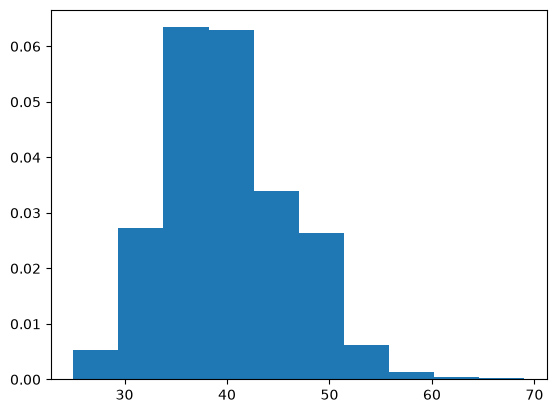

In [29]:
def bin_neg(p, r, N):
    amostra = []
    for i in range(N):
        u = np.random.uniform()
        n = r
        pn = p**r
        F = pn
        while u > F:
            pn = pn * (n*(1-p)/(n-r+1))
            n += 1
            F += pn
        amostra.append(n)
    
    return amostra

p = 0.5
r = 20
N = 1000

dados = bin_neg_geom(p, r, N)

plt.hist(dados, density=True)
plt.show()

Hipergeométrica via Fisher-Yates

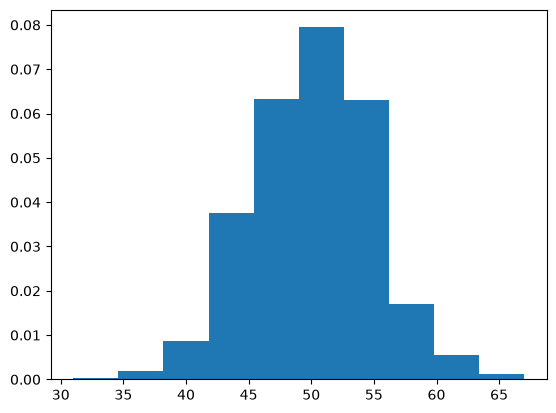

In [30]:
def hipergeometrica(N, M, n, K):
    amostra = []
    conjunto = N*[1] + M*[0]
    for i in range(K):
      elemn = conjunto.copy()
      for j in range(n):
        random = int(np.random.uniform()*(N+M-(j+1)))+(j+1)
        elemn[j], elemn[random] = elemn[random], elemn[j]
      amostra.append(np.sum(elemn[:n]))
    return amostra

N = 1_000
M = 1_000
n = 100
K = 1_000

dados = hipergeometrica(N, M, n, K)

plt.hist(dados, density=True)
plt.show()

# Continuas

Exponencial

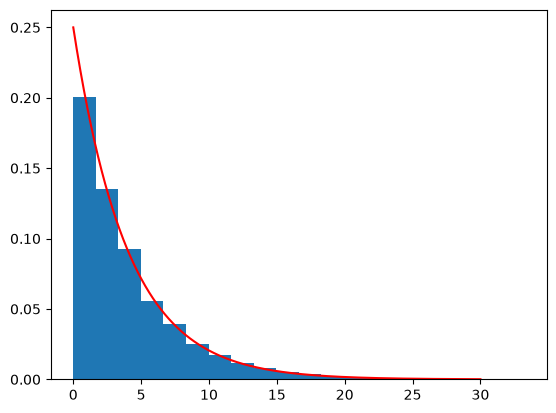

In [21]:
def exponencial(lam, M):
  amostra = []
  for i in range(M):
    x = (-1/lam) * np.log(np.random.uniform())
    amostra.append(x)
  
  return amostra

M = 10_000
lam = 0.25

dados = exponencial(lam, M)

x = np.linspace(0, 30, M)
y = lam * np.exp(-lam * x)

plt.hist(dados, density=True, bins=20)
plt.plot(x, y, color='red')
plt.show()

Normal via aceitação-rejeição

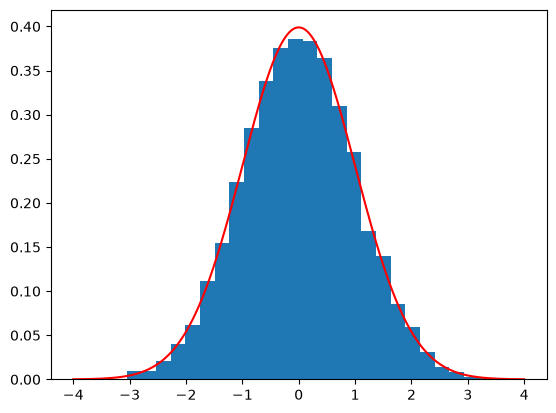

In [5]:
def f_normal(x):
  return 2*np.exp(-(x**2)/2)/np.sqrt(2*np.pi)

def g_normal(x):
  return np.exp(-x)

def normal(mi, sigma, M):
  c = 2*np.exp(1/2)/np.sqrt(2*np.pi)

  amostra = []
  while len(amostra) < M:
    u = np.random.uniform()
    y = (-1) * np.log(np.random.uniform())

    if(u < f_normal(y)/(c*g_normal(y))):
      amostra.append(y)

  for i in range(len(amostra)):
    if(np.random.uniform() < 0.5):
      amostra[i] = -amostra[i]

  if(mi != 0 or sigma != 1):
    for i in range(len(amostra)):
      amostra[i] = (amostra[i] * sigma) + mi

  return amostra

valor = []
for x in np.linspace(-4, 4, 10_000):
  valor.append(f_normal(x)/2)

dados = normal(0, 1, 10_000)

plt.hist(dados, density=True, bins=30)
plt.plot(np.linspace(-4, 4, 10_000), valor, color='red')
plt.show()

Gama via soma de exponencial

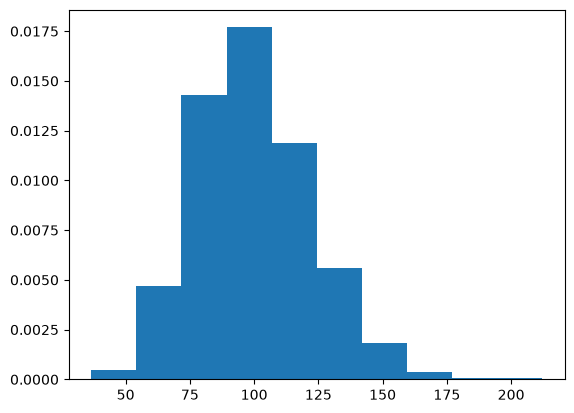

In [ ]:
def gama_exp(k, lam, M):
  amostra = []
  for i in range(M):
    valor = []
    for j in range(k):
      x = (-1/lam) * np.log(np.random.uniform())
      valor.append(x)
    amostra.append(sum(valor))

  return amostra

dados = gama_exp(20, 1/5, 10_000)

plt.hist(dados, density=True)
plt.show()

Gama via aceitação-rejeição

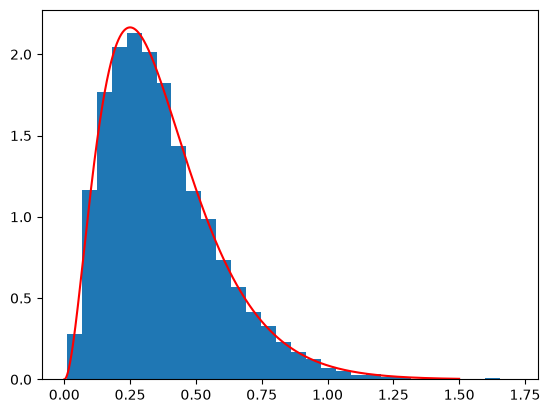

In [11]:
def f_gama(x, alpha, beta):
  return (beta**alpha)/(math.gamma(alpha)) * x**(alpha-1) * np.exp(-beta * x)

def g_gama(x, lam):
  return lam*np.exp(-lam*x)

def gama(alpha, beta, M):
  lam = beta/alpha
  c = (beta**alpha)/(math.gamma(alpha) * lam) * ((alpha-1)/(beta-lam))**(alpha-1) * np.exp(-(alpha-1))
  amostra = []

  while len(amostra) < M:
    u = np.random.uniform()
    y = (-1/lam) * np.log(np.random.uniform())

    if(u < f_gama(y, alpha, beta)/(c*g_gama(y, lam))):
      amostra.append(y)

  return amostra

valor = []
for x in np.linspace(0, 1.5, 10_000):
  valor.append(f_gama(x, 3, 8))

dados = gama(3, 8, 10_000)

plt.hist(dados, density=True, bins=30)
plt.plot(np.linspace(0, 1.5, 10_000), valor, color='red')
plt.show()

Gama via G*U (Para alpha < 1)

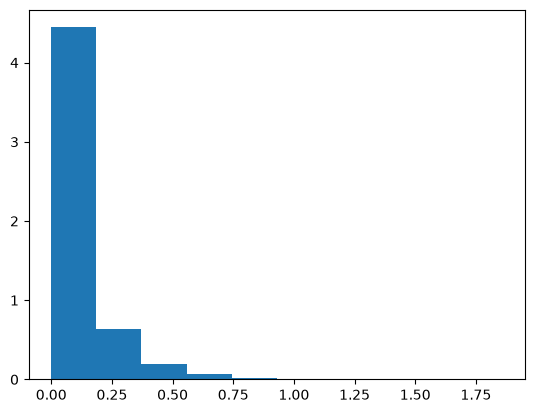

In [38]:
def gama_gu(alpha, beta, M):
    return gama(alpha+1, beta, M) * (np.random.uniform(size=M)**(1/alpha))

dados = gama_gu(0.5, 5, 10_000)

plt.hist(dados, density=True)
plt.show()

Beta via aceitação-rejeição

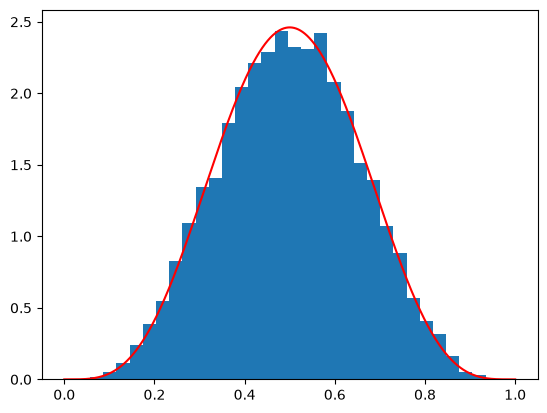

In [17]:
def f_beta(x, alpha, beta):
  return math.gamma(alpha + beta)/(math.gamma(alpha)*math.gamma(beta)) * x**(alpha-1) * (1-x)**(beta-1)

def beta(alpha, beta, M):
    valor = []
    for x in np.linspace(0, 1, M):
        valor.append(f_beta(x, alpha, beta))

    c = np.max(valor)+0.05

    amostra = []

    while len(amostra) < M:
        u = np.random.uniform()
        y = np.random.uniform()

        if(u < f_beta(y, alpha, beta)/c):
            amostra.append(y)

    return amostra

valor = []
for x in np.linspace(0, 1, 10_000):
  valor.append(f_beta(x, 5, 5))

dados = beta(5, 5, 10_000)

plt.hist(dados, density=True, bins=30)
plt.plot(np.linspace(0, 1, 10_000), valor, color='red')
plt.show()

Beta via G1/(G1+G2)

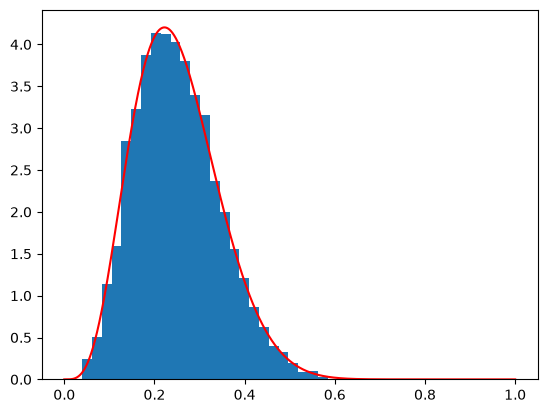

In [14]:
def beta_transform(alpha, beta, M):

    G1 = np.array(gama(alpha, 1, M))
    G2 = np.array(gama(beta, 1, M))

    return G1/(G1+G2)

valor = []
for x in np.linspace(0, 1, 10_000):
  valor.append(f_beta(x, 5, 15))

dados = beta_transform(5, 15, 10_000)

plt.hist(dados, density=True, bins=30)
plt.plot(np.linspace(0, 1, 10_000), valor, color='red')
plt.show()